In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/shilongzhuang/telecom-customer-churn-by-maven-analytics/telecom_customer_churn.csv
/kaggle/input/datasets/shilongzhuang/telecom-customer-churn-by-maven-analytics/telecom_data_dictionary.csv
/kaggle/input/datasets/shilongzhuang/telecom-customer-churn-by-maven-analytics/telecom_zipcode_population.csv


In [2]:
customer_data = pd.read_csv('/kaggle/input/datasets/shilongzhuang/telecom-customer-churn-by-maven-analytics/telecom_customer_churn.csv')

In [3]:
customer_data.head()

,Customer ID,Gender,Age,Married,Number of Dependents,City,Zip Code,Latitude,Longitude,Number of Referrals,...,Payment Method,Monthly Charge,Total Charges,Total Refunds,Total Extra Data Charges,Total Long Distance Charges,Total Revenue,Customer Status,Churn Category,Churn Reason
0,0002-ORFBO,Female,37,Yes,0,Frazier Park,93225,34.827662,-118.999073,2,...,Credit Card,65.6,593.30,0.00,0,381.51,974.81,Stayed,NaN,NaN
1,0003-MKNFE,Male,46,No,0,Glendale,91206,34.162515,-118.203869,0,...,Credit Card,-4.0,542.40,38.33,10,96.21,610.28,Stayed,NaN,NaN
2,0004-TLHLJ,Male,50,No,0,Costa Mesa,92627,33.645672,-117.922613,0,...,Bank Withdrawal,73.9,280.85,0.00,0,134.60,415.45,Churned,Competitor,Competitor had better devices
3,0011-IGKFF,Male,78,Yes,0,Martinez,94553,38.014457,-122.115432,1,...,Bank Withdrawal,98.0,1237.85,0.00,0,361.66,1599.51,Churned,Dissatisfaction,Product dissatisfaction
4,0013-EXCHZ,Female,75,Yes,0,Camarillo,93010,34.227846,-119.079903,3,...,Credit Card,83.9,267.40,0.00,0,22.14,289.54,Churned,Dissatisfaction,Network reliability


In [4]:
customer_data.shape

(7043, 38)

In [5]:
customer_data.columns

Index(['Customer ID', 'Gender', 'Age', 'Married', 'Number of Dependents',
       'City', 'Zip Code', 'Latitude', 'Longitude', 'Number of Referrals',
       'Tenure in Months', 'Offer', 'Phone Service',
       'Avg Monthly Long Distance Charges', 'Multiple Lines',
       'Internet Service', 'Internet Type', 'Avg Monthly GB Download',
       'Online Security', 'Online Backup', 'Device Protection Plan',
       'Premium Tech Support', 'Streaming TV', 'Streaming Movies',
       'Streaming Music', 'Unlimited Data', 'Contract', 'Paperless Billing',
       'Payment Method', 'Monthly Charge', 'Total Charges', 'Total Refunds',
       'Total Extra Data Charges', 'Total Long Distance Charges',
       'Total Revenue', 'Customer Status', 'Churn Category', 'Churn Reason'],
      dtype='object')

In [6]:
customer_data.isnull().sum()

Customer ID                             0
Gender                                  0
Age                                     0
Married                                 0
Number of Dependents                    0
City                                    0
Zip Code                                0
Latitude                                0
Longitude                               0
Number of Referrals                     0
Tenure in Months                        0
Offer                                3877
Phone Service                           0
Avg Monthly Long Distance Charges     682
Multiple Lines                        682
Internet Service                        0
Internet Type                        1526
Avg Monthly GB Download              1526
Online Security                      1526
Online Backup                        1526
Device Protection Plan               1526
Premium Tech Support                 1526
Streaming TV                         1526
Streaming Movies                  

In [7]:
customer_data['Internet Service'].value_counts()

Internet Service
Yes    5517
No     1526
Name: count, dtype: int64

In [8]:
customer_data['Phone Service'].value_counts()

Phone Service
Yes    6361
No      682
Name: count, dtype: int64

In [9]:
customer_data['Offer'].value_counts(dropna=False)

Offer
NaN        3877
Offer B     824
Offer E     805
Offer D     602
Offer A     520
Offer C     415
Name: count, dtype: int64

In [10]:
data_dictionary = pd.read_csv('/kaggle/input/datasets/shilongzhuang/telecom-customer-churn-by-maven-analytics/telecom_data_dictionary.csv',encoding='latin1')

data_dictionary.head(10)

,Table,Field,Description
0,Customer Churn,CustomerID,A unique ID that identifies each customer
1,Customer Churn,Gender,"The customers gender: Male, Female"
2,Customer Churn,Age,"The customers current age, in years, at the t..."
3,Customer Churn,Married,"Indicates if the customer is married: Yes, No"
4,Customer Churn,Number of Dependents,Indicates the number of dependents that live w...
5,Customer Churn,City,The city of the customers primary residence i...
6,Customer Churn,Zip Code,The zip code of the customers primary residence
7,Customer Churn,Latitude,The latitude of the customers primary residence
8,Customer Churn,Longitude,The longitude of the customers primary residence
9,Customer Churn,Number of Referrals,Indicates the number of times the customer has...


In [11]:
data_dictionary[data_dictionary.iloc[:, 1] == 'Offer']

,Table,Field,Description
11,Customer Churn,Offer,Identifies the last marketing offer that the c...


In [12]:
customer_data['Customer Status'].value_counts()

Customer Status
Stayed     4720
Churned    1869
Joined      454
Name: count, dtype: int64

In [13]:
model_data = customer_data[

    customer_data['Customer Status'].isin(['Stayed', 'Churned'])

].copy()

In [14]:
model_data['Customer Status'].value_counts()

Customer Status
Stayed     4720
Churned    1869
Name: count, dtype: int64

In [15]:
model_data['Customer Status'].value_counts(normalize=True)

Customer Status
Stayed     0.716345
Churned    0.283655
Name: proportion, dtype: float64

In [16]:
model_data.dtypes

Customer ID                           object
Gender                                object
Age                                    int64
Married                               object
Number of Dependents                   int64
City                                  object
Zip Code                               int64
Latitude                             float64
Longitude                            float64
Number of Referrals                    int64
Tenure in Months                       int64
Offer                                 object
Phone Service                         object
Avg Monthly Long Distance Charges    float64
Multiple Lines                        object
Internet Service                      object
Internet Type                         object
Avg Monthly GB Download              float64
Online Security                       object
Online Backup                         object
Device Protection Plan                object
Premium Tech Support                  object
Streaming 

In [17]:
model_data['Churn'] = model_data['Customer Status'].map({'Stayed': 0,'Churned': 1})

model_data[['Customer Status', 'Churn']].head(10)

,Customer Status,Churn
0,Stayed,0
1,Stayed,0
2,Churned,1
3,Churned,1
4,Churned,1
5,Stayed,0
6,Stayed,0
7,Stayed,0
8,Stayed,0
9,Stayed,0


In [18]:
model_data['Churn'].value_counts()

Churn
0    4720
1    1869
Name: count, dtype: int64

In [19]:
y = model_data['Churn']
y.head()

0    0
1    0
2    1
3    1
4    1
Name: Churn, dtype: int64

In [20]:
features = ['Gender','Age','Married','Number of Dependents','Number of Referrals','Tenure in Months','Offer',
'Phone Service','Avg Monthly Long Distance Charges','Multiple Lines','Internet Service','Internet Type','Avg Monthly GB Download',
'Online Security','Online Backup','Device Protection Plan','Premium Tech Support','Streaming TV','Streaming Movies',
'Streaming Music','Unlimited Data','Contract','Paperless Billing','Payment Method','Monthly Charge','Total Charges',
'Total Refunds','Total Extra Data Charges','Total Long Distance Charges','Total Revenue']


In [21]:
X = model_data[features].copy()
X.head()
X.shape

(6589, 30)

In [22]:
X.isnull().sum()

Gender                                  0
Age                                     0
Married                                 0
Number of Dependents                    0
Number of Referrals                     0
Tenure in Months                        0
Offer                                3598
Phone Service                           0
Avg Monthly Long Distance Charges     644
Multiple Lines                        644
Internet Service                        0
Internet Type                        1344
Avg Monthly GB Download              1344
Online Security                      1344
Online Backup                        1344
Device Protection Plan               1344
Premium Tech Support                 1344
Streaming TV                         1344
Streaming Movies                     1344
Streaming Music                      1344
Unlimited Data                       1344
Contract                                0
Paperless Billing                       0
Payment Method                    

In [23]:
categorical_cols = X.select_dtypes(include='object').columns

categorical_cols

Index(['Gender', 'Married', 'Offer', 'Phone Service', 'Multiple Lines',
       'Internet Service', 'Internet Type', 'Online Security', 'Online Backup',
       'Device Protection Plan', 'Premium Tech Support', 'Streaming TV',
       'Streaming Movies', 'Streaming Music', 'Unlimited Data', 'Contract',
       'Paperless Billing', 'Payment Method'],
      dtype='object')

In [24]:
numerical_cols = X.select_dtypes(exclude='object').columns

numerical_cols

Index(['Age', 'Number of Dependents', 'Number of Referrals',
       'Tenure in Months', 'Avg Monthly Long Distance Charges',
       'Avg Monthly GB Download', 'Monthly Charge', 'Total Charges',
       'Total Refunds', 'Total Extra Data Charges',
       'Total Long Distance Charges', 'Total Revenue'],
      dtype='object')

In [25]:
categorical_cols = X.select_dtypes(include='object').columns

numerical_cols = X.select_dtypes(exclude='object').columns

In [26]:
X[categorical_cols] = X[categorical_cols].fillna('None')
X[numerical_cols] = X[numerical_cols].fillna(X[numerical_cols].median())

In [27]:
X.isnull().sum().sum()

np.int64(0)

In [28]:
from sklearn.model_selection import train_test_split

train_X, val_X, train_y, val_y = train_test_split(X, y,test_size=0.2,random_state=1,stratify=y)

train_X.shape, val_X.shape

((5271, 30), (1318, 30))

In [29]:
train_X = pd.get_dummies(train_X, columns=categorical_cols, dtype=int)
val_X = pd.get_dummies(val_X, columns=categorical_cols, dtype=int)

In [30]:
train_X, val_X = train_X.align(val_X, join='left', axis=1, fill_value=0)
train_X.shape, val_X.shape

((5271, 65), (1318, 65))

In [31]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression(max_iter=1000, random_state=1)
model.fit(train_X, train_y)


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression(max_iter=1000, random_state=1)

In [32]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

train_X_scaled = train_X.copy()

val_X_scaled = val_X.copy()

train_X_scaled[numerical_cols] = scaler.fit_transform(train_X[numerical_cols])

val_X_scaled[numerical_cols] = scaler.transform(val_X[numerical_cols])

In [33]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000, random_state=1)

model.fit(train_X_scaled, train_y)

LogisticRegression(max_iter=1000, random_state=1)

In [34]:
val_predictions = model.predict(val_X_scaled)

val_predictions[:10]

array([0, 0, 1, 0, 1, 0, 0, 0, 0, 0])

In [35]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(val_y, val_predictions)

print("Accuracy:", accuracy)

Accuracy: 0.8467374810318664


In [36]:
from sklearn.metrics import classification_report

print(classification_report(val_y, val_predictions))

              precision    recall  f1-score   support

           0       0.89      0.90      0.89       944
           1       0.74      0.71      0.72       374

    accuracy                           0.85      1318
   macro avg       0.81      0.81      0.81      1318
weighted avg       0.85      0.85      0.85      1318



In [37]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(val_y, val_predictions)

print(cm)

[[850  94]
 [108 266]]


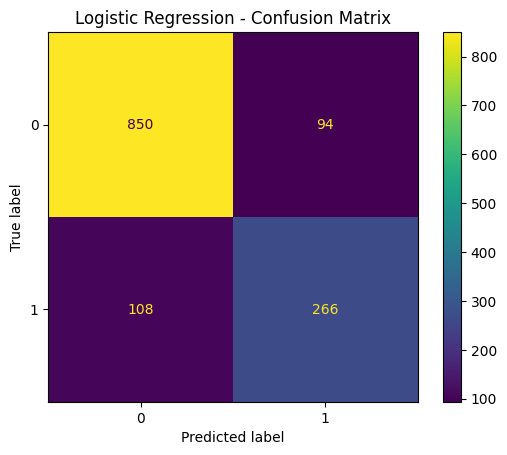

In [38]:
import matplotlib.pyplot as plt

from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(val_y, val_predictions)

plt.title("Logistic Regression - Confusion Matrix")

plt.show()

In [39]:
from sklearn.metrics import roc_auc_score

val_probabilities = model.predict_proba(val_X_scaled)[:, 1]

roc_auc = roc_auc_score(val_y, val_probabilities)

print("ROC-AUC:", roc_auc)

ROC-AUC: 0.9076633735158162


In [40]:
from sklearn.tree import DecisionTreeClassifier

tree_model = DecisionTreeClassifier(max_depth=5,random_state=1)
tree_model.fit(train_X, train_y)

DecisionTreeClassifier(max_depth=5, random_state=1)

In [41]:
tree_predictions = tree_model.predict(val_X)

In [42]:
tree_accuracy = accuracy_score(val_y, tree_predictions)

print("Decision Tree Accuracy:", tree_accuracy)

Decision Tree Accuracy: 0.8452200303490136


In [43]:
print(classification_report(val_y, tree_predictions))

              precision    recall  f1-score   support

           0       0.90      0.89      0.89       944
           1       0.72      0.74      0.73       374

    accuracy                           0.85      1318
   macro avg       0.81      0.81      0.81      1318
weighted avg       0.85      0.85      0.85      1318



In [44]:
from sklearn.ensemble import RandomForestClassifier
forest_model = RandomForestClassifier(n_estimators=200,random_state=1,n_jobs=-1)
forest_model.fit(train_X, train_y)

RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=1)

In [45]:
forest_predictions = forest_model.predict(val_X)

In [46]:
forest_accuracy = accuracy_score(val_y, forest_predictions)

print("Random Forest Accuracy:", forest_accuracy)

Random Forest Accuracy: 0.8687405159332322


In [47]:
print(classification_report(val_y, forest_predictions))

              precision    recall  f1-score   support

           0       0.88      0.95      0.91       944
           1       0.84      0.67      0.74       374

    accuracy                           0.87      1318
   macro avg       0.86      0.81      0.83      1318
weighted avg       0.87      0.87      0.86      1318



In [48]:
forest_probabilities = forest_model.predict_proba(val_X)[:, 1]

forest_roc_auc = roc_auc_score(val_y, forest_probabilities)

print("Random Forest ROC-AUC:", forest_roc_auc)

Random Forest ROC-AUC: 0.9203327517447657


In [49]:
logistic_accuracy = accuracy_score(val_y, val_predictions)
tree_accuracy = accuracy_score(val_y, tree_predictions)
forest_accuracy = accuracy_score(val_y, forest_predictions)
print("Model Performance")
print("-------------------------")
print("Logistic Regression:", logistic_accuracy)
print("Decision Tree:", tree_accuracy)
print("Random Forest:", forest_accuracy)

Model Performance
-------------------------
Logistic Regression: 0.8467374810318664
Decision Tree: 0.8452200303490136
Random Forest: 0.8687405159332322


In [50]:
logistic_roc_auc = roc_auc_score(val_y,model.predict_proba(val_X_scaled)[:, 1])
tree_roc_auc = roc_auc_score(val_y,tree_model.predict_proba(val_X)[:, 1])
forest_roc_auc = roc_auc_score(val_y,forest_model.predict_proba(val_X)[:, 1])
print("ROC-AUC Comparison")
print("-------------------------")
print("Logistic Regression:", logistic_roc_auc)
print("Decision Tree:", tree_roc_auc)
print("Random Forest:", forest_roc_auc)

ROC-AUC Comparison
-------------------------
Logistic Regression: 0.9076633735158162
Decision Tree: 0.8997014637904469
Random Forest: 0.9203327517447657


In [51]:
feature_importance = pd.Series(forest_model.feature_importances_,index=train_X.columns)
feature_importance = feature_importance.sort_values(ascending=False)
feature_importance.head(15)

Tenure in Months                     0.111763
Contract_Month-to-Month              0.093715
Total Charges                        0.082708
Total Revenue                        0.080702
Number of Referrals                  0.056621
Monthly Charge                       0.053562
Age                                  0.049742
Total Long Distance Charges          0.047610
Avg Monthly Long Distance Charges    0.037219
Avg Monthly GB Download              0.033423
Contract_Two Year                    0.031816
Online Security_No                   0.025915
Number of Dependents                 0.021371
Premium Tech Support_No              0.020364
Internet Type_Fiber Optic            0.013086
dtype: float64

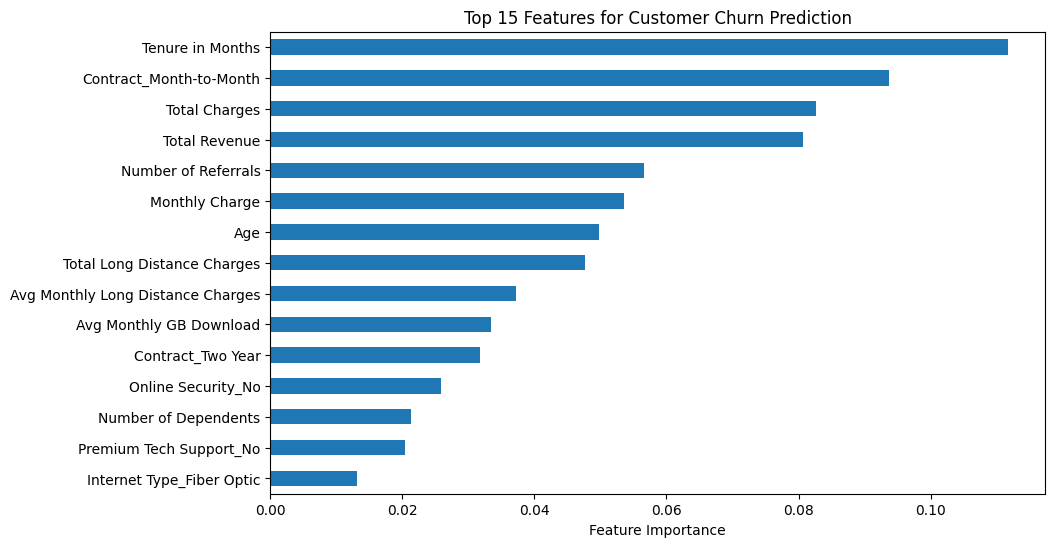

In [52]:
feature_importance.head(15).sort_values().plot(kind='barh',figsize=(10, 6))
plt.title("Top 15 Features for Customer Churn Prediction")
plt.xlabel("Feature Importance")
plt.show()

In [53]:
results = pd.DataFrame({"Model": ["Logistic Regression","Decision Tree","Random Forest"],
"Accuracy": [logistic_accuracy,tree_accuracy,forest_accuracy],
"ROC-AUC": [logistic_roc_auc,tree_roc_auc,forest_roc_auc]})
results

,Model,Accuracy,ROC-AUC
0,Logistic Regression,0.846737,0.907663
1,Decision Tree,0.845220,0.899701
2,Random Forest,0.868741,0.920333


In [54]:
best_model_name = results.loc[results["ROC-AUC"].idxmax(),"Model"]

print("Best Model:", best_model_name)

Best Model: Random Forest


In [55]:
import joblib

joblib.dump(forest_model, "customer_churn_random_forest.pkl")

['customer_churn_random_forest.pkl']

In [56]:
joblib.dump(train_X.columns.tolist(), "churn_feature_names.pkl")

['churn_feature_names.pkl']

In [57]:
results.to_csv("model_results.csv", index=False)